Text(0, 0.5, 'Resting HR (bpm)')

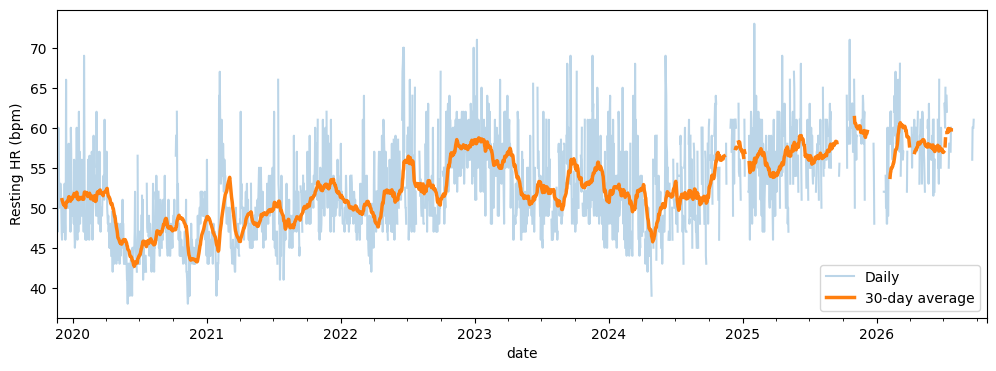

In [12]:
import xml.etree.ElementTree as ET # load Python's built-in XML reader
import pandas as pd # library to handle table

rows = []
for _, el in ET.iterparse("apple_health_export/export.xml"):
    if el.tag == "Record" and el.get("type") == "HKQuantityTypeIdentifierRestingHeartRate": # keep only Record tag whose type is resting heart rate
        rows.append({"date": el.get("startDate")[:10], "rhr": float(el.get("value"))})
    el.clear()  # free memory

rhr_raw = pd.DataFrame(rows) # turns into a table with columns date and rhr
rhr_raw["date"] = pd.to_datetime(rhr_raw["date"]) # converts the date into real dates
rhr_raw = rhr_raw.groupby("date").mean() # if a day has more than one value, average them into one
rhr_daily = rhr_raw.asfreq("D") # empty rows for days with no value.
rhr_daily["rolling_30d"] = rhr_daily["rhr"].rolling('30D', min_periods=15).mean() # 30-day average
ax = rhr_daily["rhr"].plot(alpha=0.3, label="Daily", figsize=(12, 4)) 
rhr_daily["rolling_30d"].plot(ax=ax, linewidth=2.5, label="30-day average")
ax.legend()
ax.set_ylabel("Resting HR (bpm)")

Text(0, 0.5, 'HRV SDNN (ms)')

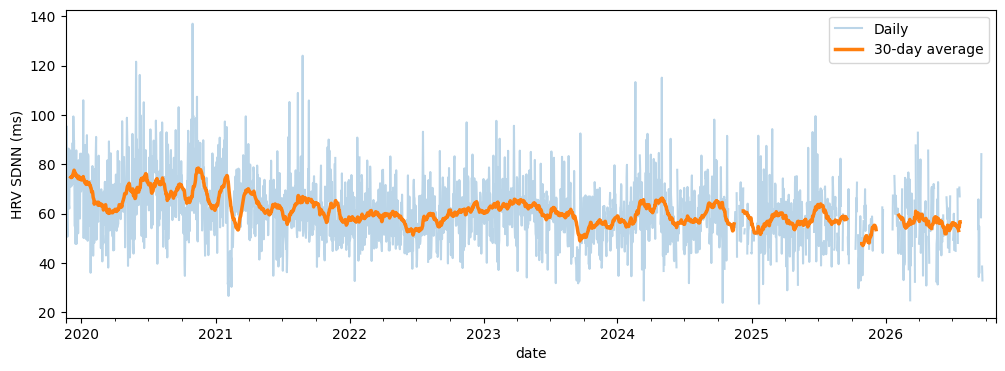

In [15]:
import xml.etree.ElementTree as ET # load Python's built-in XML reader
import pandas as pd # library to handle table

hrv_rows = [] # list
for _, el in ET.iterparse("apple_health_export/export.xml"):
    if el.tag == "Record" and el.get("type") == "HKQuantityTypeIdentifierHeartRateVariabilitySDNN": # keep only Record tag whose type is resting heart rate
        hrv_rows.append({"date": el.get("startDate")[:10], "hrv": float(el.get("value"))})
    el.clear()  # free memory

hrv_raw = pd.DataFrame(hrv_rows) # turns into a table with columns date and hrv
hrv_raw["date"] = pd.to_datetime(hrv_raw["date"]) # converts the date into real dates
hrv_raw = hrv_raw.groupby("date").mean() # if a day has more than one value, average them into one
hrv_daily = hrv_raw.asfreq("D") # empty rows for days with no value.
hrv_daily["rolling_30d"] = hrv_daily["hrv"].rolling('30D', min_periods=15).mean() # 30-day average
ax = hrv_daily["hrv"].plot(alpha=0.3, label="Daily", figsize=(12, 4)) 
hrv_daily["rolling_30d"].plot(ax=ax, linewidth=2.5, label="30-day average")
ax.legend()
ax.set_ylabel("HRV SDNN (ms)")

